# Binary Router Experiment: B vs Other

This notebook trains **Random Forest** and **XGBoost** binary classifiers under both split strategies used in the project:

- **`strat_y`** — stratify on the binary target.
- **`strat_y_K`** — stratify on the combined binary target + `k_value`, using the project's K-aware split helper.

For every model/split combination, metrics are reported on both:

1. **Held-out test data** — the primary generalization result.
2. **Entire usable dataset** — a descriptive/resubstitution result because it contains the training rows.

Exact cross-group runtime ties are reported and excluded rather than expanded into contradictory binary labels.

## 1. Binary target

`B` when the fastest of the six `-B-` algorithms is strictly below the fastest of the other 18 algorithms; `Other` for the reverse.

Ties *inside* a group do not make the binary target ambiguous. Only an exact tie between the best runtime of the two competing groups is excluded.

The notebook keeps one row per original `(dataset, k)` instance; there is **no tie expansion** for this binary routing experiment.

In [11]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, confusion_matrix,
    ConfusionMatrixDisplay, classification_report,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "restructured_pipeline").exists():
    # Supports launching Jupyter from a subdirectory inside the repository.
    for parent in Path.cwd().resolve().parents:
        if (parent / "restructured_pipeline").exists():
            REPO_ROOT = parent
            break
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from restructured_pipeline.src.features import (
    algorithms as ALL_ALGOS,
    feature_cols as PIPELINE_FEATURE_COLS,
    load_excel_data,
    process_kcore_list_to_statistics,
    post_process_data,
    ROUTER_CLASSB_ALGOS,
)
from restructured_pipeline.src.data_splits import _train_test_split_k_aware

try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError("xgboost is required for this notebook") from exc

PROJECT_CONFIG_PATH = REPO_ROOT / "restructured_pipeline/configs/project.yaml"
MODEL_CONFIG_PATH = REPO_ROOT / "restructured_pipeline/configs/models_scheme1.yaml"
OUTPUT_DIR = REPO_ROOT / "restructured_pipeline/outputs/reports/binary_B_vs_other_classifier"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

with open(PROJECT_CONFIG_PATH, "r", encoding="utf-8") as f:
    project = yaml.safe_load(f)
with open(MODEL_CONFIG_PATH, "r", encoding="utf-8") as f:
    model_cfg = yaml.safe_load(f)

FEATURE_COLS = list(project.get("features", {}).get("feature_cols", PIPELINE_FEATURE_COLS))
TEST_SIZE = project["split_rules"]["defaults"]["test_size"]
RANDOM_STATE = project["split_rules"]["defaults"]["random_state"]
TARGET_COL = "binary_target"
LABELS = ['B', 'Other']
SPLIT_MODES = ("strat_y", "strat_y_K")

print("Features:", FEATURE_COLS)
print("test_size:", TEST_SIZE, "random_state:", RANDOM_STATE)
print("labels:", LABELS)

Features: ['k_value', 'n', 'm', 'd_avg', 'd_max', 'core_max', 'core_min', 'shell_num', 'shell_avgSize', 'shell_maxSize', 'shell_minSize', 'shell_stdSize']
test_size: 0.2 random_state: 42
labels: ['B', 'Other']


## 2. Load and preprocess the canonical data

`load_excel_data()` loads the runtime table. The configured feature set also contains derived core/shell statistics, so the notebook calls the existing `process_kcore_list_to_statistics()` and `post_process_data()` utilities before validation.

In [12]:
data_cfg = project["data"]
df = load_excel_data(
    data_cfg["file_path"],
    timeout_replacement=data_cfg["timeout_replacement"],
    y_cols=data_cfg["raw_target_columns"],
    sep=data_cfg["sep"],
    quotechar=data_cfg["quotechar"],
    engine=data_cfg["engine"],
    rename_columns=data_cfg["rename_columns"],
)

if "kcore_list" in df.columns and any(c not in df.columns for c in ["core_min", "shell_num", "shell_avgSize", "shell_maxSize", "shell_minSize", "shell_stdSize"]):
    process_kcore_list_to_statistics(df, keep_col=False)
df = post_process_data(df)

required = ["dataset", "k_value", *FEATURE_COLS, *ALL_ALGOS]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns after preprocessing: {missing}")

# Preserve a stable original-row identity for leakage checks and exported split indices.
df = df.copy()
df["source_row_index"] = df.index
print("Original rows after canonical loading/preprocessing:", len(df))
display(df[["dataset", *FEATURE_COLS]].head())

Original rows after canonical loading/preprocessing: 4279


,dataset,k_value,n,m,d_avg,d_max,core_max,core_min,shell_num,shell_avgSize,shell_maxSize,shell_minSize,shell_stdSize
0,12month1,20,52328,1585220,30.294,9214,57,19,39,16785.102564,52328,1030,14354.722410
1,130bit,8,584,6059,10.375,322,12,8,5,564.400000,584,509,28.443628
2,130bit,9,584,6059,10.375,322,12,8,5,564.400000,584,509,28.443628
3,130bit,10,583,6051,10.379,321,12,9,4,559.500000,583,509,29.853810
4,144,4,144319,1072349,7.430,26,9,7,3,140266.333333,144319,132943,5188.210310


## 3. Construct and audit the binary target

Exact cross-group ties are excluded from both training and evaluation. The audit table is intended to be reported alongside the model metrics so the excluded population is transparent.

In [13]:
B_ALGOS = list(ROUTER_CLASSB_ALGOS)
OTHER_ALGOS = [a for a in ALL_ALGOS if a not in B_ALGOS]
assert len(B_ALGOS) == 6 and len(OTHER_ALGOS) == 18
print("B algorithms:", B_ALGOS)

def construct_binary_target(frame):
    out = frame.copy()
    b_min = out[B_ALGOS].min(axis=1)
    other_min = out[OTHER_ALGOS].min(axis=1)
    out["left_best_runtime"] = b_min
    out["right_best_runtime"] = other_min
    out["is_cross_group_tie"] = np.isclose(b_min, other_min, rtol=0.0, atol=0.0)
    out[TARGET_COL] = np.where(b_min < other_min, "B", "Other")
    ties = out[out["is_cross_group_tie"]].copy()
    usable = out[~out["is_cross_group_tie"]].copy()
    return usable, ties

binary_df, tie_df = construct_binary_target(df)

class_counts = binary_df[TARGET_COL].value_counts().reindex(LABELS, fill_value=0)
audit_df = pd.DataFrame({
    "Measure": ["Original rows", "Usable unambiguous rows", "Excluded exact cross-group ties", *[f"Class: {x}" for x in LABELS]],
    "Count": [len(df), len(binary_df), len(tie_df), *[int(class_counts[x]) for x in LABELS]],
})
audit_df["Percent of original"] = (100 * audit_df["Count"] / len(df)).round(2)
display(audit_df)


B algorithms: ['kPEX-B-bnb', 'kPEX-oriented-B-bnb', 'UMKP-B-bnb', 'UMKP-oriented-B-bnb', 'UMKP+-B-bnb', 'UMKP+-oriented-B-bnb']


,Measure,Count,Percent of original
0,Original rows,4279,100.00
1,Usable unambiguous rows,3810,89.04
2,Excluded exact cross-group ties,469,10.96
3,Class: B,1560,36.46
4,Class: Other,2250,52.58


## 4. Build both project split strategies

**`strat_y`** uses a standard stratified 80/20 split on the binary target.

**`strat_y_K`** uses the project's `_train_test_split_k_aware()` helper on the **original, unexpanded rows**, stratifying on `binary_target + k_value`. Rare combined classes may be forced into training by that helper so the remaining target+K stratification is feasible.

The notebook checks that train/test source-row overlap is zero and that held-out rows are unique.

In [14]:
def make_binary_split(frame, split_mode):
    X = frame[FEATURE_COLS].copy()
    y = frame[TARGET_COL].copy()

    if split_mode == "strat_y":
        X_train, X_test, y_train, y_test = train_test_split(
            X, y,
            test_size=TEST_SIZE,
            random_state=RANDOM_STATE,
            stratify=y,
        )
    elif split_mode == "strat_y_K":
        stratify_labels = y.astype(str) + "_k" + frame["k_value"].astype(str)
        X_train, X_test, y_train, y_test = _train_test_split_k_aware(
            X, y,
            test_size=TEST_SIZE,
            random_state=RANDOM_STATE,
            stratify_labels=stratify_labels,
            context_label=f"binary_{TARGET_COL}_strat_y_K",
        )
    else:
        raise ValueError(split_mode)

    overlap = set(X_train.index) & set(X_test.index)
    if overlap:
        raise ValueError(f"Train/test source-row overlap for {split_mode}: {sorted(overlap)[:20]}")
    if X_test.index.duplicated().any():
        raise ValueError(f"Duplicate held-out source rows for {split_mode}")

    return {"X_train": X_train, "X_test": X_test, "y_train": y_train, "y_test": y_test}

splits = {mode: make_binary_split(binary_df, mode) for mode in SPLIT_MODES}

split_audit = []
for mode, s in splits.items():
    split_audit.append({
        "Split": mode,
        "Train rows": len(s["X_train"]),
        "Test rows": len(s["X_test"]),
        "Overlap": len(set(s["X_train"].index) & set(s["X_test"].index)),
        "Duplicate test rows": int(s["X_test"].index.duplicated().sum()),
        **{f"Train {lab}": int((s["y_train"] == lab).sum()) for lab in LABELS},
        **{f"Test {lab}": int((s["y_test"] == lab).sum()) for lab in LABELS},
    })
split_audit_df = pd.DataFrame(split_audit)
display(split_audit_df)

binary_binary_target_strat_y_K: forced 0 row(s) into training before the K-aware split.
binary_binary_target_strat_y_K: completed true target+K stratification on 22 combined class(es).
binary_binary_target_strat_y_K: final train/test sizes = 3048/762.


,Split,Train rows,Test rows,Overlap,Duplicate test rows,Train B,Train Other,Test B,Test Other
0,strat_y,3048,762,0,0,1248,1800,312,450
1,strat_y_K,3048,762,0,0,1247,1801,313,449


## 5. Reuse RF/XGB configuration

For each split mode, the notebook uses the corresponding Scheme 1 variant configuration (`rf_strat_y`, `rf_strat_y_K`, `xgb_strat_y`, `xgb_strat_y_K`) where available. The XGB objective is changed to `binary:logistic` because this experiment has two classes.

In [15]:
def get_variant_hyperparameters(cfg, family, split_mode):
    root = cfg.get("scheme1", cfg)
    family_keys = [family, "random_forest" if family == "rf" else "xgboost", "RF" if family == "rf" else "XGB"]
    family_cfg = next((root[k] for k in family_keys if isinstance(root, dict) and k in root), {})
    variant = f"{'rf' if family == 'rf' else 'xgb'}_{split_mode}"

    # Handle common YAML layouts without overriding a valid configured variant.
    candidates = []
    if isinstance(family_cfg, dict):
        candidates += [family_cfg.get("variants", {}).get(variant), family_cfg.get(variant)]
    if isinstance(root, dict):
        candidates += [root.get("variants", {}).get(variant), root.get(variant)]
    chosen = next((x for x in candidates if isinstance(x, dict)), {})
    params = dict(chosen.get("hyperparameters", chosen))

    # Safe fallbacks matching the existing flat-model presets if YAML lookup is empty.
    if not params:
        if family == "rf":
            params = {"n_estimators": 200 if split_mode == "strat_y" else 400,
                      "max_depth": 20, "min_samples_split": 4 if split_mode == "strat_y" else 2,
                      "class_weight": "balanced", "random_state": RANDOM_STATE}
        else:
            params = {"n_estimators": 400, "max_depth": 10, "learning_rate": 0.1,
                      "subsample": 0.8, "random_state": RANDOM_STATE}
    return params

rf_params = {m: get_variant_hyperparameters(model_cfg, "rf", m) for m in SPLIT_MODES}
xgb_params = {m: get_variant_hyperparameters(model_cfg, "xgb", m) for m in SPLIT_MODES}
for m in SPLIT_MODES:
    xgb_params[m].pop("num_class", None)
    xgb_params[m]["objective"] = "binary:logistic"
    xgb_params[m]["eval_metric"] = "logloss"
    # Current XGBoost versions ignore/use_label_encoder inconsistently.
    xgb_params[m].pop("use_label_encoder", None)

print("RF parameters:", rf_params)
print("XGB parameters:", xgb_params)

RF parameters: {'strat_y': {'n_estimators': 200, 'max_depth': 20, 'min_samples_split': 4, 'class_weight': 'balanced', 'random_state': 42}, 'strat_y_K': {'n_estimators': 400, 'max_depth': 20, 'min_samples_split': 2, 'class_weight': 'balanced', 'random_state': 42}}
XGB parameters: {'strat_y': {'objective': 'binary:logistic', 'n_estimators': 400, 'max_depth': 10, 'learning_rate': 0.1, 'subsample': 0.8, 'random_state': 42, 'eval_metric': 'logloss'}, 'strat_y_K': {'objective': 'binary:logistic', 'n_estimators': 400, 'max_depth': 10, 'learning_rate': 0.1, 'subsample': 0.8, 'random_state': 42, 'eval_metric': 'logloss'}}


## 6. Train four models

There are four fitted models in this notebook:

| Split | Random Forest | XGBoost |
|---|---|---|
| `strat_y` | ✓ | ✓ |
| `strat_y_K` | ✓ | ✓ |

Each model is fitted only on its corresponding training partition.

In [16]:
trained = {}
for split_mode, s in splits.items():
    rf = RandomForestClassifier(**rf_params[split_mode])
    rf.fit(s["X_train"], s["y_train"])
    trained[(split_mode, "RF")] = {"model": rf, "encoder": None}

    le = LabelEncoder().fit(LABELS)
    y_train_enc = le.transform(s["y_train"])
    xgb = XGBClassifier(**xgb_params[split_mode])
    xgb.fit(s["X_train"], y_train_enc)
    trained[(split_mode, "XGB")] = {"model": xgb, "encoder": le}

print("Trained:", list(trained))

Trained: [('strat_y', 'RF'), ('strat_y', 'XGB'), ('strat_y_K', 'RF'), ('strat_y_K', 'XGB')]


## Wrong predictions and important routing failures

This section separates **classification errors** from **runtime-important routing errors**.

For each prediction we report the number of evaluated datapoints, correct predictions, wrong predictions, and wrong-prediction rate. A wrong routing decision is counted as an **important failure** only when:

1. the true global-optimum runtime is **greater than 5 seconds**, and
2. the best runtime available inside the **predicted branch/family** is **greater than 1.2× the global optimum**.

This evaluates the runtime consequence of the router decision. It does **not** assume that the downstream within-family algorithm selector necessarily chooses that family's optimum; therefore it is an optimistic routing-level failure analysis.


In [17]:
IMPORTANT_RUNTIME_SECONDS = 5.0
IMPORTANT_RATIO_THRESHOLD = 1.20

analysis_predictions = pd.concat(prediction_frames, ignore_index=True).copy()
analysis_predictions["true_label"] = analysis_predictions["true_label"].astype(str)
analysis_predictions["predicted_label"] = analysis_predictions["predicted_label"].astype(str)

runtime_source = binary_df

def family_best_runtime(row, label):
    if label == "B":
        return float(row[B_ALGOS].min())
    if label == "Other":
        return float(row[OTHER_ALGOS].min())
    raise ValueError(f"Unknown B/Other label: {label!r}")

def attach_runtime_consequence(r):
    src = runtime_source.loc[int(r["source_row_index"])]
    global_best = float(src[list(ALL_ALGOS)].min())
    predicted_best = family_best_runtime(src, r["predicted_label"])
    return pd.Series({"global_fastest_runtime": global_best, "predicted_branch_best_runtime": predicted_best})

analysis_predictions[["global_fastest_runtime", "predicted_branch_best_runtime"]] = analysis_predictions.apply(attach_runtime_consequence, axis=1)

analysis_predictions["wrong_prediction"] = analysis_predictions["true_label"].ne(analysis_predictions["predicted_label"])
analysis_predictions["routing_time_ratio"] = analysis_predictions["predicted_branch_best_runtime"] / analysis_predictions["global_fastest_runtime"]
analysis_predictions["important_failure"] = (
    analysis_predictions["wrong_prediction"]
    & analysis_predictions["global_fastest_runtime"].gt(IMPORTANT_RUNTIME_SECONDS)
    & analysis_predictions["routing_time_ratio"].gt(IMPORTANT_RATIO_THRESHOLD)
)

# Table 1: prediction population and ordinary classification errors.
wrong_prediction_table = (
    analysis_predictions.groupby(["split_mode", "model", "evaluation_scope"], dropna=False)
    .agg(
        total_datapoints=("source_row_index", "size"),
        correct_predictions=("wrong_prediction", lambda s: int((~s).sum())),
        wrong_predictions=("wrong_prediction", "sum"),
    )
    .reset_index()
)
wrong_prediction_table["wrong_predictions"] = wrong_prediction_table["wrong_predictions"].astype(int)
wrong_prediction_table["accuracy_percent"] = (
    100 * wrong_prediction_table["correct_predictions"] / wrong_prediction_table["total_datapoints"]
).round(2)
wrong_prediction_table["wrong_prediction_percent"] = (
    100 * wrong_prediction_table["wrong_predictions"] / wrong_prediction_table["total_datapoints"]
).round(2)

# Table 2: consequential subset of the wrong predictions.
important_failure_table = (
    analysis_predictions.groupby(["split_mode", "model", "evaluation_scope"], dropna=False)
    .agg(
        total_datapoints=("source_row_index", "size"),
        wrong_predictions=("wrong_prediction", "sum"),
        important_failures=("important_failure", "sum"),
    )
    .reset_index()
)
important_failure_table[["wrong_predictions", "important_failures"]] = important_failure_table[["wrong_predictions", "important_failures"]].astype(int)
important_failure_table["important_failures_percent_of_wrong"] = np.where(
    important_failure_table["wrong_predictions"].gt(0),
    100 * important_failure_table["important_failures"] / important_failure_table["wrong_predictions"],
    0.0,
).round(2)
important_failure_table["important_failures_percent_of_all"] = (
    100 * important_failure_table["important_failures"] / important_failure_table["total_datapoints"]
).round(2)

print("Wrong-prediction analysis")
display(wrong_prediction_table)
print("Important routing failures (>5 s global optimum and >1.2x routing ratio)")
display(important_failure_table)

wrong_prediction_table.to_csv(OUTPUT_DIR / "slide_table_wrong_predictions.csv", index=False)
important_failure_table.to_csv(OUTPUT_DIR / "slide_table_important_failures.csv", index=False)
analysis_predictions.to_csv(OUTPUT_DIR / "prediction_failure_analysis.csv", index=False)


Wrong-prediction analysis


,split_mode,model,evaluation_scope,total_datapoints,correct_predictions,wrong_predictions,accuracy_percent,wrong_prediction_percent
0,strat_y,RF,Entire data (includes training rows),3810,3441,369,90.31,9.69
1,strat_y,RF,Held-out test,762,523,239,68.64,31.36
2,strat_y,XGB,Entire data (includes training rows),3810,3509,301,92.10,7.90
3,strat_y,XGB,Held-out test,762,521,241,68.37,31.63
4,strat_y_K,RF,Entire data (includes training rows),3810,3520,290,92.39,7.61
5,strat_y_K,RF,Held-out test,762,529,233,69.42,30.58
6,strat_y_K,XGB,Entire data (includes training rows),3810,3526,284,92.55,7.45
7,strat_y_K,XGB,Held-out test,762,537,225,70.47,29.53


Important routing failures (>5 s global optimum and >1.2x routing ratio)


,split_mode,model,evaluation_scope,total_datapoints,wrong_predictions,important_failures,important_failures_percent_of_wrong,important_failures_percent_of_all
0,strat_y,RF,Entire data (includes training rows),3810,369,10,2.71,0.26
1,strat_y,RF,Held-out test,762,239,8,3.35,1.05
2,strat_y,XGB,Entire data (includes training rows),3810,301,13,4.32,0.34
3,strat_y,XGB,Held-out test,762,241,12,4.98,1.57
4,strat_y_K,RF,Entire data (includes training rows),3810,290,8,2.76,0.21
5,strat_y_K,RF,Held-out test,762,233,7,3.00,0.92
6,strat_y_K,XGB,Entire data (includes training rows),3810,284,7,2.46,0.18
7,strat_y_K,XGB,Held-out test,762,225,6,2.67,0.79


## 7. Metrics on held-out test **and** entire dataset

For each fitted model, the notebook reports:

- Accuracy
- Macro precision / recall / F1
- Weighted precision / recall / **F1**
- Per-class precision / recall / F1 and support
- Confusion matrix

**Interpretation:** held-out test metrics are the primary generalization estimates. Entire-data metrics include training instances and therefore should be labeled **Entire data (includes training rows)** on slides; they are not an independent test estimate.

In [18]:
def predict_labels(model, X_eval, encoder=None):
    pred = model.predict(X_eval)
    if encoder is not None:
        pred = encoder.inverse_transform(np.asarray(pred, dtype=int))
    return np.asarray(pred, dtype=object)

def metric_record(split_mode, model_name, scope, y_true, y_pred):
    macro = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, average="macro", zero_division=0)
    weighted = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, average="weighted", zero_division=0)
    per = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, average=None, zero_division=0)
    rec = {
        "Split": split_mode, "Model": model_name, "Evaluation Scope": scope, "Rows": len(y_true),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": macro[0], "Macro Recall": macro[1], "Macro F1": macro[2],
        "Weighted Precision": weighted[0], "Weighted Recall": weighted[1], "Weighted F1": weighted[2],
    }
    for i, lab in enumerate(LABELS):
        rec[f"{lab} Precision"] = per[0][i]
        rec[f"{lab} Recall"] = per[1][i]
        rec[f"{lab} F1"] = per[2][i]
        rec[f"{lab} Support"] = int(per[3][i])
    return rec

metric_rows = []
prediction_frames = []
for (split_mode, model_name), obj in trained.items():
    s = splits[split_mode]
    scopes = [
        ("Held-out test", s["X_test"], s["y_test"]),
        ("Entire data (includes training rows)", binary_df[FEATURE_COLS], binary_df[TARGET_COL]),
    ]
    for scope, X_eval, y_eval in scopes:
        pred = predict_labels(obj["model"], X_eval, obj["encoder"])
        metric_rows.append(metric_record(split_mode, model_name, scope, y_eval, pred))
        prediction_frames.append(pd.DataFrame({
            "source_row_index": X_eval.index,
            "split_mode": split_mode,
            "model": model_name,
            "evaluation_scope": scope,
            "true_label": np.asarray(y_eval),
            "predicted_label": pred,
        }))

metrics_df = pd.DataFrame(metric_rows)
for c in metrics_df.columns:
    if c not in {"Split", "Model", "Evaluation Scope", "Rows"} and not c.endswith("Support"):
        metrics_df[c] = pd.to_numeric(metrics_df[c], errors="coerce").round(4)
display(metrics_df)

,Split,Model,Evaluation Scope,Rows,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,B Precision,B Recall,B F1,B Support,Other Precision,Other Recall,Other F1,Other Support
0,strat_y,RF,Held-out test,762,0.6864,0.6750,0.6725,0.6735,0.6845,0.6864,0.6852,0.6221,0.5962,0.6088,312,0.7279,0.7489,0.7382,450
1,strat_y,RF,Entire data (includes training rows),3810,0.9031,0.9000,0.8996,0.8998,0.9031,0.9031,0.9031,0.8830,0.8801,0.8815,1560,0.9171,0.9191,0.9181,2250
2,strat_y,XGB,Held-out test,762,0.6837,0.6719,0.6674,0.6689,0.6808,0.6837,0.6816,0.6228,0.5769,0.5990,312,0.7209,0.7578,0.7389,450
3,strat_y,XGB,Entire data (includes training rows),3810,0.9210,0.9201,0.9161,0.9179,0.9209,0.9210,0.9208,0.9155,0.8891,0.9021,1560,0.9246,0.9431,0.9338,2250
4,strat_y_K,RF,Held-out test,762,0.6942,0.6837,0.6742,0.6768,0.6903,0.6942,0.6902,0.6471,0.5623,0.6017,313,0.7204,0.7862,0.7519,449
5,strat_y_K,RF,Entire data (includes training rows),3810,0.9239,0.9223,0.9199,0.9211,0.9238,0.9239,0.9238,0.9145,0.8981,0.9062,1560,0.9302,0.9418,0.9360,2250
6,strat_y_K,XGB,Held-out test,762,0.7047,0.6946,0.6880,0.6902,0.7017,0.7047,0.7022,0.6549,0.5942,0.6231,313,0.7343,0.7817,0.7573,449
7,strat_y_K,XGB,Entire data (includes training rows),3810,0.9255,0.9243,0.9212,0.9227,0.9254,0.9255,0.9253,0.9186,0.8974,0.9079,1560,0.9300,0.9449,0.9374,2250


## 8. Confusion matrices

A separate confusion matrix is produced for every split/model/scope combination and saved as a PNG. This makes it easy to inspect class-specific routing errors rather than relying on accuracy alone.

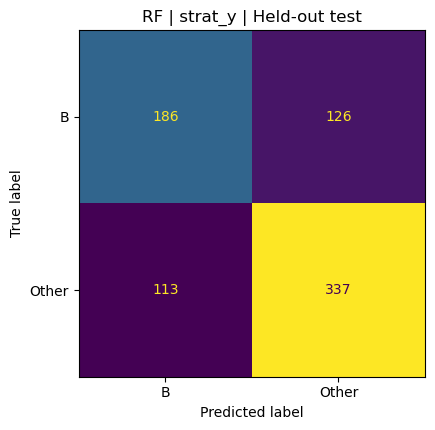

Saved: d:\Studies\Research\Da_Project\kpex_ML_git\restructured_pipeline\outputs\reports\binary_B_vs_other_classifier\confusion_matrix_strat_y_rf_test.png


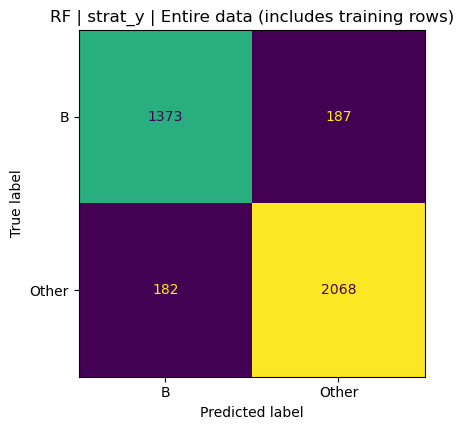

Saved: d:\Studies\Research\Da_Project\kpex_ML_git\restructured_pipeline\outputs\reports\binary_B_vs_other_classifier\confusion_matrix_strat_y_rf_entire.png


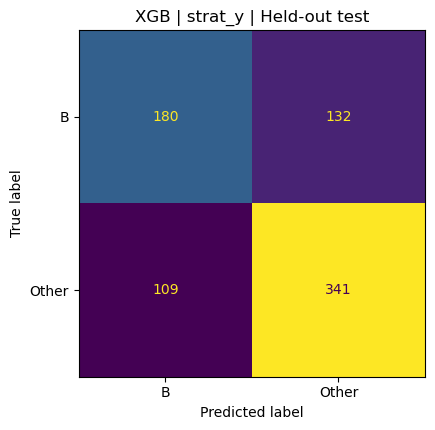

Saved: d:\Studies\Research\Da_Project\kpex_ML_git\restructured_pipeline\outputs\reports\binary_B_vs_other_classifier\confusion_matrix_strat_y_xgb_test.png


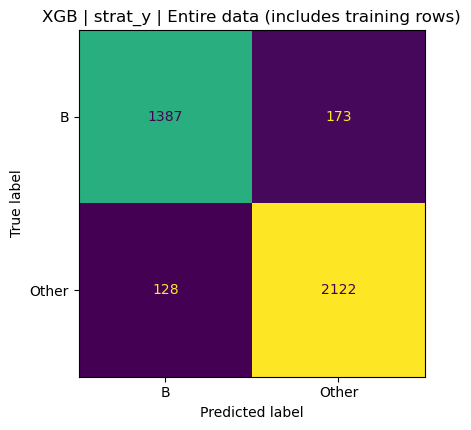

Saved: d:\Studies\Research\Da_Project\kpex_ML_git\restructured_pipeline\outputs\reports\binary_B_vs_other_classifier\confusion_matrix_strat_y_xgb_entire.png


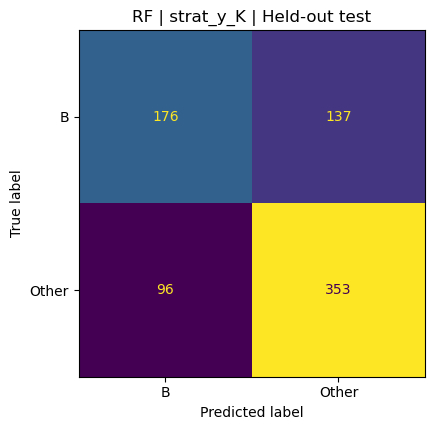

Saved: d:\Studies\Research\Da_Project\kpex_ML_git\restructured_pipeline\outputs\reports\binary_B_vs_other_classifier\confusion_matrix_strat_y_K_rf_test.png


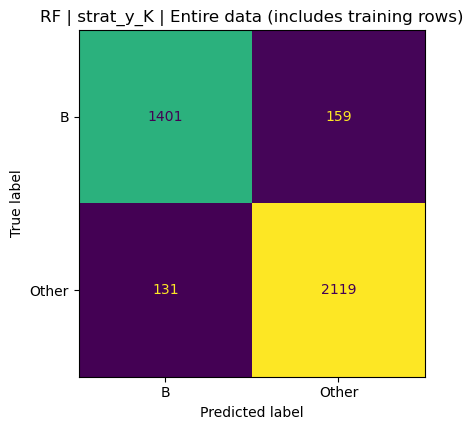

Saved: d:\Studies\Research\Da_Project\kpex_ML_git\restructured_pipeline\outputs\reports\binary_B_vs_other_classifier\confusion_matrix_strat_y_K_rf_entire.png


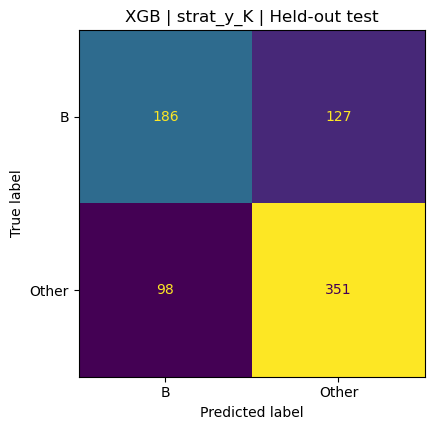

Saved: d:\Studies\Research\Da_Project\kpex_ML_git\restructured_pipeline\outputs\reports\binary_B_vs_other_classifier\confusion_matrix_strat_y_K_xgb_test.png


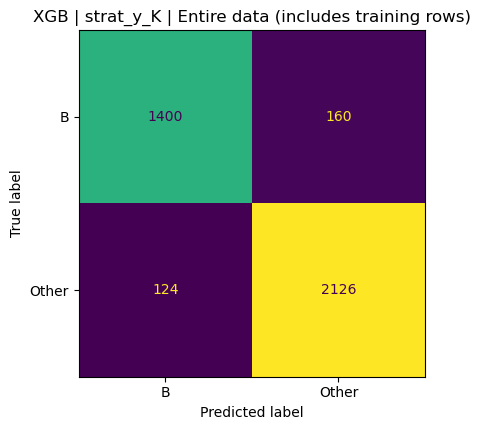

Saved: d:\Studies\Research\Da_Project\kpex_ML_git\restructured_pipeline\outputs\reports\binary_B_vs_other_classifier\confusion_matrix_strat_y_K_xgb_entire.png


In [19]:
for pf in prediction_frames:
    # Each frame here corresponds to one model/split/scope.
    split_mode = pf["split_mode"].iloc[0]
    model_name = pf["model"].iloc[0]
    scope = pf["evaluation_scope"].iloc[0]
    y_true = pf["true_label"]
    y_pred = pf["predicted_label"]
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    fig, ax = plt.subplots(figsize=(5.2, 4.4))
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, values_format="d", cmap=None, colorbar=False)
    ax.set_title(f"{model_name} | {split_mode} | {scope}")
    fig.tight_layout()
    safe_scope = "test" if scope.startswith("Held-out") else "entire"
    path = OUTPUT_DIR / f"confusion_matrix_{split_mode}_{model_name.lower()}_{safe_scope}.png"
    fig.savefig(path, dpi=180, bbox_inches="tight")
    plt.show()
    print("Saved:", path)

## 9. Slide-ready comparison tables

### Table A — Primary held-out results
Use this table on the main results slide. It compares RF and XGB under both stratification strategies on unseen held-out rows.

### Table B — Test vs entire-data accuracy/F1
Use this as a compact secondary table when you want to show the gap between held-out generalization and performance over the complete usable dataset.

Values are displayed as percentages for presentation.

In [20]:
def as_percent_table(frame, cols):
    out = frame[cols].copy()
    metric_cols = [c for c in out.columns if c not in {"Split", "Model", "Evaluation Scope", "Rows"}]
    for c in metric_cols:
        out[c] = (100 * pd.to_numeric(out[c], errors="coerce")).round(1)
    return out

primary = metrics_df[metrics_df["Evaluation Scope"].eq("Held-out test")]
primary_cols = [
    "Split", "Model", "Rows", "Accuracy", "Weighted F1",
    "B Precision", "B Recall", "B F1", "Other Precision", "Other Recall", "Other F1"
]
slide_primary = as_percent_table(primary, primary_cols)
print("TABLE A — HELD-OUT TEST RESULTS (%)")
display(slide_primary)

compact_cols = ["Split", "Model", "Evaluation Scope", "Rows", "Accuracy", "Weighted F1"]
slide_test_entire = as_percent_table(metrics_df, compact_cols)
print("TABLE B — TEST VS ENTIRE DATA (%)")
display(slide_test_entire)

# Optional pivot: one row per split/model for a very compact slide.
pivot = metrics_df.pivot_table(index=["Split", "Model"], columns="Evaluation Scope", values=["Accuracy", "Weighted F1"]).reset_index()
pivot.columns = [" | ".join([str(x) for x in col if str(x)]) if isinstance(col, tuple) else col for col in pivot.columns]
for c in pivot.columns:
    if c not in {"Split", "Model"}:
        pivot[c] = (100 * pivot[c]).round(1)
print("TABLE C — COMPACT GENERALIZATION GAP (%)")
display(pivot)

TABLE A — HELD-OUT TEST RESULTS (%)


,Split,Model,Rows,Accuracy,Weighted F1,B Precision,B Recall,B F1,Other Precision,Other Recall,Other F1
0,strat_y,RF,762,68.6,68.5,62.2,59.6,60.9,72.8,74.9,73.8
2,strat_y,XGB,762,68.4,68.2,62.3,57.7,59.9,72.1,75.8,73.9
4,strat_y_K,RF,762,69.4,69.0,64.7,56.2,60.2,72.0,78.6,75.2
6,strat_y_K,XGB,762,70.5,70.2,65.5,59.4,62.3,73.4,78.2,75.7


TABLE B — TEST VS ENTIRE DATA (%)


,Split,Model,Evaluation Scope,Rows,Accuracy,Weighted F1
0,strat_y,RF,Held-out test,762,68.6,68.5
1,strat_y,RF,Entire data (includes training rows),3810,90.3,90.3
2,strat_y,XGB,Held-out test,762,68.4,68.2
3,strat_y,XGB,Entire data (includes training rows),3810,92.1,92.1
4,strat_y_K,RF,Held-out test,762,69.4,69.0
5,strat_y_K,RF,Entire data (includes training rows),3810,92.4,92.4
6,strat_y_K,XGB,Held-out test,762,70.5,70.2
7,strat_y_K,XGB,Entire data (includes training rows),3810,92.6,92.5


TABLE C — COMPACT GENERALIZATION GAP (%)


,Split,Model,Accuracy | Entire data (includes training rows),Accuracy | Held-out test,Weighted F1 | Entire data (includes training rows),Weighted F1 | Held-out test
0,strat_y,RF,90.3,68.6,90.3,68.5
1,strat_y,XGB,92.1,68.4,92.1,68.2
2,strat_y_K,RF,92.4,69.4,92.4,69.0
3,strat_y_K,XGB,92.6,70.5,92.5,70.2


## 10. Save outputs

The notebook saves the full metrics table, slide-ready tables, predictions, target audit, split audit, tie rows, and exact train/test source indices. These files make the experiment reproducible and make it easier to move results into slides.

In [21]:
metrics_df.to_csv(OUTPUT_DIR / "metrics_test_and_entire.csv", index=False)
slide_primary.to_csv(OUTPUT_DIR / "slide_table_heldout.csv", index=False)
slide_test_entire.to_csv(OUTPUT_DIR / "slide_table_test_vs_entire.csv", index=False)
pivot.to_csv(OUTPUT_DIR / "slide_table_compact_gap.csv", index=False)
audit_df.to_csv(OUTPUT_DIR / "target_audit.csv", index=False)
split_audit_df.to_csv(OUTPUT_DIR / "split_audit.csv", index=False)
tie_df.to_csv(OUTPUT_DIR / "excluded_cross_group_ties.csv", index=False)
pd.concat(prediction_frames, ignore_index=True).to_csv(OUTPUT_DIR / "predictions_test_and_entire.csv", index=False)

for mode, s in splits.items():
    pd.DataFrame({"source_row_index": s["X_train"].index}).to_csv(OUTPUT_DIR / f"train_indices_{mode}.csv", index=False)
    pd.DataFrame({"source_row_index": s["X_test"].index}).to_csv(OUTPUT_DIR / f"test_indices_{mode}.csv", index=False)

print("Saved outputs to:", OUTPUT_DIR)

Saved outputs to: d:\Studies\Research\Da_Project\kpex_ML_git\restructured_pipeline\outputs\reports\binary_B_vs_other_classifier


## 11. How to present this experiment

A clean slide sequence is:

1. **Question:** Can graph features predict the coarse routing decision **B vs Other**?
2. **Method:** one binary label per original instance; exact cross-group ties excluded; RF and XGB; both `strat_y` and `strat_y_K`.
3. **Primary table:** Table A (held-out test results). Emphasize **Weighted F1** plus both classes' recall/F1, not accuracy alone.
4. **Generalization check:** Table B or C. A large entire-data vs held-out gap indicates overfitting; do not present entire-data accuracy as test accuracy.
5. **Confusion matrices:** show the best held-out RF/XGB configurations to explain which routing direction is harder.

For model selection, prioritize the **held-out test metrics**. Entire-data metrics are useful diagnostics but include training observations.